<h2 align="center">Character Bidirectional LSTM Model<h2>

<p>Trying to train basic language identification character bidirectional lstm  model in intra-word code-switching<p>

## Import needed libraries 

In [2]:
# import the needed libraries
import pandas as pd
import os
import numpy as np
from keras.models import Sequential
from keras.layers import LSTM
from keras.layers import Dense
from keras.layers import TimeDistributed
from sklearn.model_selection import train_test_split
from keras.preprocessing.sequence import pad_sequences
from keras.models import Model, Input
from keras.layers import LSTM, Embedding, Dense, TimeDistributed, Dropout, Conv1D
from keras.layers import Bidirectional, concatenate, SpatialDropout1D, GlobalMaxPooling1D
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

ModuleNotFoundError: No module named 'keras'

## Load the data 

In [1]:
DataPath = '../../Data Collection and Annotation/Data.csv'
Data = pd.read_csv(DataPath)
display(Data.head(10))
print(Data.shape)

NameError: name 'pd' is not defined

In [4]:
# extract the (token,segment,tag,SegmentLen) from the data
agg_func = lambda s: [(w, p, t, l) for w, p, t, l in zip(s["Token"].values.tolist(),s["Segment"].values.tolist(),s["Tag-Mixed"].values.tolist(),s["SegmentLen"].values.tolist())]

# grouped the data with its sentence to separate the sentence by a newline
grouped = Data.groupby("Sentence#").apply(agg_func)
sentences = [s for s in grouped]

# split the sentences into train and test sets by 800:229 ratio
train, test = train_test_split(sentences, test_size=0.222546161, random_state=2018)

## Helper Methods

In [32]:
# split the word into char list
def split(word): 
    return [char for char in word] 

# convert tag into its ids list
def tagtoid(tag):
    word_seq = []
    for i in range(len(tag)):
        try:
             word_seq.append(tag2idx.get(tag[i]))
        except:
             word_seq.append(tag2idx.get("PAD"))
    return word_seq

# get the tags for every char
def getLanguageforEachChar(index):
    charLang = []
    seglen = Data["SegmentLen"][index].split(",")
    tags = Data["Tag-Mixed"][index].split(",")
    out=[]
    for i in range(0,len(seglen)):
        out.append(int(seglen[i]))
    seglen = out
    for i in range(0,len(seglen)):
        for j in range(0,seglen[i]):
            charLang.append(tags[i])
    return charLang

# get the maximum length in tokens 
def getLenOflongword():
    leng = 0
    tokens = Data["Token"]
    for i in range(0,len(tokens)):
        if(len(tokens[i])>int(leng)):
            leng = len(tokens[i])
    return leng

# extend the small tokens to make all input in one length by adding zeros
def extendTooneLength(wordList,leng):
    out = wordList
    for i in range(len(wordList),leng):
        out.append(0)
    return out

# convert tokens into its ids list
def tokentoid(token):
    word_seq = []
    for i in range(len(token)):
        try:
             word_seq.append(char2idx.get(token[i]))
            
        except:
             word_seq.append(char2idx.get("PAD"))
    return word_seq

# make sequences of the token and tags
def get_char_sequence(token, segmentLen, tagMixed):
    listWord = split(token)
    seglen = segmentLen.split(",")
    tags = tagMixed.split(",")
    out=[]
    listlang = []
    for i in range(0,len(seglen)):
        out.append(int(seglen[i]))
    seglen = out
    for i in range(0,len(seglen)):
        for j in range(0,seglen[i]):
            listlang.append(tags[i])
    return listWord,listlang

# make sequences of the 2 and 3 grams 
def get_ngram_sequence(token):
    listWord = split(token)
    n2gram = list()
    n3gram = list()
    for j in range(0,len(listWord)):
        a = listWord[j]
        if(j!=len(listWord)-1):
            a += listWord[j+1]
        n2gram.append(a)
    for j in range(0,len(listWord)):
        a = listWord[j]
        if(j!=0):
            a = listWord[j-1] + a
        if(j!=len(listWord)-1):
            a += listWord[j+1]
        n3gram.append(a)
    return n2gram,n3gram

# convert the nested list to one list
def onelist(inplist):
    out = []
    for s in inplist:
        for w in s:
            out.append(w)
    return out

# convert the token and tags list to strings
def seguenceGen(charList,tagList):
    outCharlist =[]
    outTaglist =[]
    lenlist = len(tagList)
    seg = ""
    for i in range(lenlist):
        seg += charList[i]
        if(i< lenlist-1):
            if(tagList[i]!=tagList[i+1]):
                outTaglist.append(str(tagList[i]+","))
                outCharlist.append(seg)
                seg = ""
        else:
            outTaglist.append(tagList[i])    
            outCharlist.append(seg)
    outTag = ""
    outSegment = ""
    for j in range(len(outCharlist)):
        outTag += str(outTaglist[j])
        outSegment += str(outCharlist[j]) + "/"+str(outTaglist[j])
    return outTag,outSegment

# prepare the lists of tokens and tags
def allListToTag(tokens,tags):
    outtokenList = []
    outtagList = []
    for token,tag in zip(tokens,tags):
        X,Y = seguenceGen(token,tag)
        outtokenList.append(Y)
        outtagList.append(X)
    return outtokenList,outtagList

# convert the ids to chars
def idToChar(listChar):
    outToken = []
    for s in listChar:
        out = []
        for w in s:
            if(w!=0):
                out.append(idx2char[w])
        outToken.append(out)
    return outToken

# convert the char list to token
def ListToToken(listChar):
    outToken = ""
    for j in range(len(listChar)):
        outToken += str(listChar[j])
    return outToken

# test the model
def predict(inputStr,gram=0):
    chars = split(inputStr)
    X1 = [[char2idx[w] for w in chars]]
    if gram == 1:
        # if the model need 2 gram feature only
        ngram = list()
        for j in range(0,len(chars)):
            a = chars[j]
            if(j!=len(chars)-1):
                a += chars[j+1]
            ngram.append(a)
        X2 = [[n2gram2idx[w] for w in ngram]]
        X_word = pad_sequences(maxlen=18, sequences=X1, value=char2idx["PAD"], padding='post', truncating='post')
        X_ngram_word = pad_sequences(maxlen=18, sequences=X2, value=n2gram2idx["PAD"], padding='post', truncating='post')
        y_pred = model.predict([np.array(X_word).reshape(1, 18),np.array(X_ngram_word).reshape(1, 18)])
    elif gram == 2:
        # if the model need 3 gram feature only
        ngram = list()
        for j in range(0,len(chars)):
            a = chars[j]
            if(j!=0):
                a = chars[j-1] + a
            if(j!=len(chars)-1):
                a += chars[j+1]
            ngram.append(a)
        X2 = [[n3gram2idx[w] for w in ngram]]
        X_word = pad_sequences(maxlen=18, sequences=X1, value=char2idx["PAD"], padding='post', truncating='post')
        X_ngram_word = pad_sequences(maxlen=18, sequences=X2, value=n3gram2idx["PAD"], padding='post', truncating='post')
        y_pred = model.predict([np.array(X_word).reshape(1, 18),np.array(X_ngram_word).reshape(1, 18)])
    elif gram == 3:
        # if the model need 2 and 3 gram features
        n2gram = list()
        for j in range(0,len(chars)):
            a = chars[j]
            if(j!=len(chars)-1):
                a += chars[j+1]
            n2gram.append(a)
        X2 = [[n2gram2idx[w] for w in n2gram]]
        n3gram = list()
        for j in range(0,len(chars)):
            a = chars[j]
            if(j!=0):
                a = chars[j-1] + a
            if(j!=len(chars)-1):
                a += chars[j+1]
            n3gram.append(a)
        X3 = [[n3gram2idx[w] for w in n3gram]]
        X_word = pad_sequences(maxlen=18, sequences=X1, value=char2idx["PAD"], padding='post', truncating='post')
        X_n2gram_word = pad_sequences(maxlen=18, sequences=X2, value=n2gram2idx["PAD"], padding='post', truncating='post')
        X_n3gram_word = pad_sequences(maxlen=18, sequences=X3, value=n3gram2idx["PAD"], padding='post', truncating='post')
        y_pred = model3.predict([np.array(X_word).reshape(1, 18),np.array(X_n2gram_word).reshape(1, 18),np.array(X_n3gram_word).reshape(1, 18)])
    else:
        X_word = pad_sequences(maxlen=18, sequences=X1, value=char2idx["PAD"], padding='post', truncating='post')
        y_pred = model.predict([np.array(X_word).reshape(1, 18)])
    p = np.argmax(y_pred[0], axis=-1)
    out=[]
    for w,pred in zip(X_word[0], p):
        if w != 0:
            out.append(pred)
    out = [idx2tag[w] for w in out]
        
    A,seg = seguenceGen(chars,out)
    
    return A,seg

# test the model with some sentences
def predicts(sentence,gram):
    out = []
    for word in sentence:
        out += predict(word,gram)
    return out

# get the features and the tags
def all_data_to_sequence(data):
    X_word = []
    X_n2gram_word = []
    X_n3gram_word = []
    Y_word = []
    for sent in data:
        for token in sent:
            X,Y = get_char_sequence(token[0],token[3],token[2])
            X_word.append(X)
            Y_word.append(Y)
            X_2,X_3 = get_ngram_sequence(token[0])
            X_n2gram_word.append(X_2)
            X_n3gram_word.append(X_3)
    return X_word, X_n2gram_word, X_n3gram_word, Y_word

# get the segments of the sequence of tags
def get_segment(inp):
    if(len(inp)==1): return [1]
    out=[]
    fchar = inp[0]
    le = 0
    for i in inp:
        if(i!=fchar):
            out.append(le)
            le = 1
            fchar = i
        else:
            le = le+1
    out.append(le)
    return out

def seg_list_to_seg(segList):
    if(len(segList)<1): return ""
    seg = ""
    for i in range(len(segList)-1):
        seg = seg+str(segList[i])+","
    seg = seg+str(segList[len(segList)-1])
    return seg

# out the predicted value and actual values to lists
def get_data(X_word_te,y_te,y_pred):
    outtoken = []
    outtag = []
    outpred = []
    outseg = []
    outpredseg = []
    for i in range(len(X_word_te)):
        p = np.argmax(y_pred[i], axis=-1)
        outtokeni = []
        outtagi = []
        outpredi = []
        for w, t, pred in zip(X_word_te[i], y_te[i], p):
            if w != 0:
                outtokeni.append(w)
                outtagi.append(t)
                outpredi.append(pred)
        outsegi = seg_list_to_seg(get_segment(outtagi))
        outpredsegi = seg_list_to_seg(get_segment(outpredi))

        outtoken.append(outtokeni)
        outtag.append(outtagi)
        outpred.append(outpredi)
        outseg.append(outsegi)
        outpredseg.append(outpredsegi)

    yacttagall = [[idx2tag[w] for w in s] for s in outtag]
    ypredtagall = [[idx2tag[w] for w in s] for s in outpred]
    TokenList = idToChar(X_word_te)
    Token = [ListToToken(s) for s in TokenList]
    _,yacttagall = allListToTag(TokenList,yacttagall)
    Segment,ypredtagall = allListToTag(TokenList,ypredtagall)
    
    tags = ["AR","EN","NE.AR","NE.EN","OTHER","AMBIG","LANG3"]
    actstagMix,predstagMix,segsMix,segpredsMix = [],[],[],[]
    for act, pred, seg, segpred in zip(yacttagall,ypredtagall,outseg,outpredseg):
        if(not(act in tags) or not(pred in tags)):
            actstagMix.append(act)
            predstagMix.append(pred)
            segsMix.append(seg)
            segpredsMix.append(segpred)

    return Token,yacttagall,ypredtagall,outseg,outpredseg,actstagMix,predstagMix,segsMix,segpredsMix,Segment

# get character accuracy which is assigning a tag for each character and then calculating the number of correct tags of all characters.
def get_Char_accuracy(acTags, acSegs, predTags, predSegs):
    total_num = 0.0
    TP = 0.0
    for acTag, acSeg, predTag, predSeg in zip(acTags, acSegs, predTags, predSegs):
        preds = []
        acts = []
        for i,j in zip(acSeg.split(","),acTag.split(",")):
            acts= acts+ ([j]*int(i))
            total_num = total_num+int(i)
        for i,j in zip(predSeg.split(","),predTag.split(",")):
            preds= preds+ ([j]*int(i))
        for i, j in zip(preds,acts):
            if(i==j):
                TP=TP+1.0
    return (TP/total_num)

## Prepare the data 

In [6]:
# get the length of the longest token in the data
biglen = getLenOflongword()

# Generate the input Features and the Y-output
X_word_tr, X_n2gram_word_tr, X_n3gram_word_tr, y_tr = all_data_to_sequence(train)
X_word_te, X_n2gram_word_te, X_n3gram_word_te, y_te = all_data_to_sequence(test)

# list of unique tokens
words = list(set(Data["Token"].values))

# get number of unique words
n_words = len(words)

# list of unique chars
chars = set(onelist(X_word_tr+X_word_te))

# get number of unique chars
n_chars = len(chars)

# list of unique 2 gram 
n2gram = set(onelist(X_n2gram_word_tr+X_n2gram_word_te))

# get number of unique 2 gram
n_n2gram = len(n2gram)

# list of unique 3 gram
n3gram = set(onelist(X_n3gram_word_tr+X_n3gram_word_te))

# get number of unique 3 gram
n_n3gram = len(n3gram)

# list of unique tags
tags = set(onelist(y_tr+y_te))

# get number of unique tags
n_tags = len(tags)

# create a dictionary to convert from tag to id
tag2idx = {c: i + 2 for i, c in enumerate(tags)}
tag2idx["PAD"] = 0

# create a dictionary to convert from char to id
char2idx = {c: i + 2 for i, c in enumerate(chars)}
char2idx["UNK"] = 1
char2idx["PAD"] = 0

# create a dictionary to convert from 2 gram to id
n2gram2idx = {c: i + 2 for i, c in enumerate(n2gram)}
n2gram2idx["UNK"] = 1
n2gram2idx["PAD"] = 0

# create a dictionary to convert from 3 gram to id
n3gram2idx = {c: i + 2 for i, c in enumerate(n3gram)}
n3gram2idx["UNK"] = 1
n3gram2idx["PAD"] = 0

# create a dictionary to convert from id to tag
idx2tag = {i: w for w, i in tag2idx.items()}
# create a dictionary to convert from id to char
idx2char = {i: w for w, i in char2idx.items()}
# create a dictionary to convert from id to 2 gram
idx2n2gram = {i: w for w, i in n2gram2idx.items()}
# create a dictionary to convert from id to 3 gram
idx2n3gram = {i: w for w, i in n3gram2idx.items()}

# Convert the input Features and the Y-output to ids
X_word_tr = [[char2idx[w] for w in s] for s in X_word_tr]
X_n2gram_word_tr = [[n2gram2idx[w] for w in s] for s in X_n2gram_word_tr]
X_n3gram_word_tr = [[n3gram2idx[w] for w in s] for s in X_n3gram_word_tr]
y_tr = [[tag2idx[w] for w in s] for s in y_tr]
X_word_te = [[char2idx[w] for w in s] for s in X_word_te]
X_n2gram_word_te = [[n2gram2idx[w] for w in s] for s in X_n2gram_word_te]
X_n3gram_word_te = [[n3gram2idx[w] for w in s] for s in X_n3gram_word_te]
y_te = [[tag2idx[w] for w in s] for s in y_te]

# make all tokens and Y-output in the same length equal to 18
X_word_tr = pad_sequences(maxlen=18, sequences=X_word_tr, value=char2idx["PAD"], padding='post', truncating='post')
X_n2gram_word_tr = pad_sequences(maxlen=18, sequences=X_n2gram_word_tr, value=n2gram2idx["PAD"], padding='post', truncating='post')
X_n3gram_word_tr = pad_sequences(maxlen=18, sequences=X_n3gram_word_tr, value=n3gram2idx["PAD"], padding='post', truncating='post')
y_tr = pad_sequences(maxlen=18, sequences=y_tr, value=tag2idx["PAD"], padding='post', truncating='post')
X_word_te = pad_sequences(maxlen=18, sequences=X_word_te, value=char2idx["PAD"], padding='post', truncating='post')
X_n2gram_word_te = pad_sequences(maxlen=18, sequences=X_n2gram_word_te, value=n2gram2idx["PAD"], padding='post', truncating='post')
X_n3gram_word_te = pad_sequences(maxlen=18, sequences=X_n3gram_word_te, value=n3gram2idx["PAD"], padding='post', truncating='post')
y_te = pad_sequences(maxlen=18, sequences=y_te, value=tag2idx["PAD"], padding='post', truncating='post')

# print an train exmple features
print("Train:")
print([idx2char[s] for s in X_word_tr[2]])
print([idx2n2gram[s] for s in X_n2gram_word_tr[2]])
print([idx2n3gram[s] for s in X_n3gram_word_tr[2]])

# print an test exmple features
print("\nTest:")
print([idx2char[s] for s in X_word_te[5]])
print([idx2n2gram[s] for s in X_n2gram_word_te[5]])
print([idx2n3gram[s] for s in X_n3gram_word_te[5]])

Train:
['s', 'h', 'a', 'r', '7', 'o', 'PAD', 'PAD', 'PAD', 'PAD', 'PAD', 'PAD', 'PAD', 'PAD', 'PAD', 'PAD', 'PAD', 'PAD']
['sh', 'ha', 'ar', 'r7', '7o', 'o', 'PAD', 'PAD', 'PAD', 'PAD', 'PAD', 'PAD', 'PAD', 'PAD', 'PAD', 'PAD', 'PAD', 'PAD']
['sh', 'sha', 'har', 'ar7', 'r7o', '7o', 'PAD', 'PAD', 'PAD', 'PAD', 'PAD', 'PAD', 'PAD', 'PAD', 'PAD', 'PAD', 'PAD', 'PAD']

Test:
['ب', 'ر', 'د', 'PAD', 'PAD', 'PAD', 'PAD', 'PAD', 'PAD', 'PAD', 'PAD', 'PAD', 'PAD', 'PAD', 'PAD', 'PAD', 'PAD', 'PAD']
['بر', 'رد', 'د', 'PAD', 'PAD', 'PAD', 'PAD', 'PAD', 'PAD', 'PAD', 'PAD', 'PAD', 'PAD', 'PAD', 'PAD', 'PAD', 'PAD', 'PAD']
['بر', 'برد', 'رد', 'PAD', 'PAD', 'PAD', 'PAD', 'PAD', 'PAD', 'PAD', 'PAD', 'PAD', 'PAD', 'PAD', 'PAD', 'PAD', 'PAD', 'PAD']


## The Model trained on char Feature

In [8]:
# input and embedding for character
token_in = Input(shape=(18,))
emb_token = Embedding(input_dim=n_chars + 2, output_dim=20,
                     input_length=18, mask_zero=True)(token_in)

# main LSTM
main_lstm = Bidirectional(LSTM(units=50, return_sequences=True,
                               recurrent_dropout=0.6))(emb_token)

out = TimeDistributed(Dense(n_tags + 2, activation="softmax"))(main_lstm)

model = Model([token_in], out)

In [9]:
# add the hyperparameters of the model
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["acc"])

In [10]:
model.summary()

Model: "model_2"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_2 (InputLayer)         (None, 18)                0         
_________________________________________________________________
embedding_2 (Embedding)      (None, 18, 20)            5100      
_________________________________________________________________
bidirectional_2 (Bidirection (None, 18, 100)           28400     
_________________________________________________________________
time_distributed_2 (TimeDist (None, 18, 9)             909       
Total params: 34,409
Trainable params: 34,409
Non-trainable params: 0
_________________________________________________________________


In [11]:
# Train the model
history = model.fit(np.array(X_word_tr).reshape(len(X_word_tr), 18),
                    np.array(y_tr).reshape(len(y_tr), 18, 1),
                    batch_size=32, epochs=50, validation_split=0.1, verbose=1)


Train on 21085 samples, validate on 2343 samples
Epoch 1/50
21085/21085 [==============================] - 20s 966us/step - loss: 0.1602 - acc: 0.7929 - val_loss: 0.0960 - val_acc: 0.8748
Epoch 2/50
21085/21085 [==============================] - 20s 930us/step - loss: 0.0972 - acc: 0.8689 - val_loss: 0.0825 - val_acc: 0.8842
Epoch 3/50
21085/21085 [==============================] - 18s 874us/step - loss: 0.0881 - acc: 0.8767 - val_loss: 0.0766 - val_acc: 0.8947
Epoch 4/50
21085/21085 [==============================] - 18s 869us/step - loss: 0.0829 - acc: 0.8868 - val_loss: 0.0752 - val_acc: 0.8952
Epoch 5/50
21085/21085 [==============================] - 19s 904us/step - loss: 0.0785 - acc: 0.8907 - val_loss: 0.0697 - val_acc: 0.9076
Epoch 6/50
21085/21085 [==============================] - 19s 897us/step - loss: 0.0761 - acc: 0.8945 - val_loss: 0.0677 - val_acc: 0.9041
Epoch 7/50
21085/21085 [==============================] - 18s 859us/step - loss: 0.0737 - acc: 0.8998 - val_loss: 0.

### Model Statics

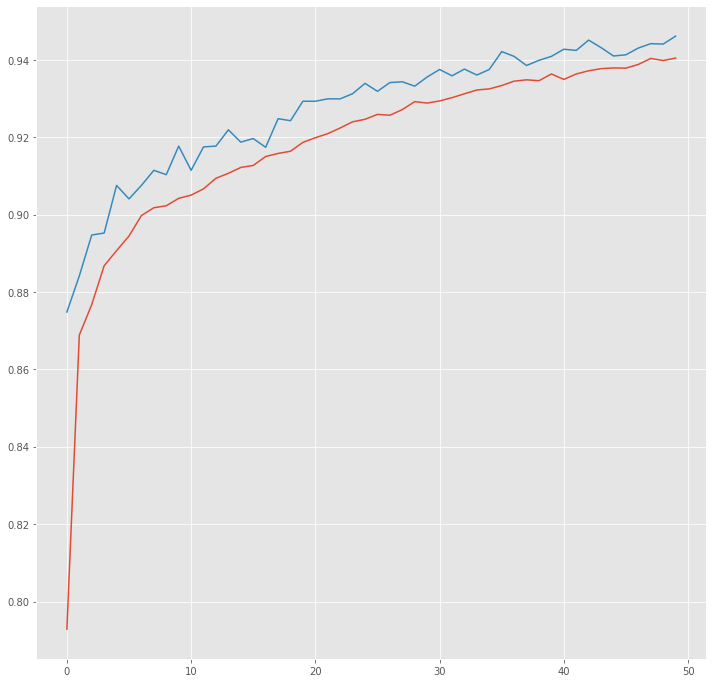

In [12]:
# Plot the acc and val_acc through the training process
hist = pd.DataFrame(history.history)
plt.style.use("ggplot")
plt.figure(figsize=(12,12))
plt.plot(hist["acc"])
plt.plot(hist["val_acc"])
plt.show()

In [13]:
# evaluate the model over the testing data
y_pred = model.predict(np.array(X_word_te).reshape(len(X_word_te), 18))

In [17]:
# out the predicted value and actual values to lists
Token,yacttagall,ypredtagall,segall,predsegall,actstagMix,predstagMix,segsMix,segpredsMix,Segment= get_data(X_word_te,y_te,y_pred)

In [19]:
# Measure accuracy
print(accuracy_score(yacttagall,ypredtagall))
print(accuracy_score(actstagMix,predstagMix))

0.9062817350935732
0.29979035639413


In [21]:
# Print the classification report for all test and mixed data tagging including the F-score
print(classification_report(yacttagall,ypredtagall,digits=4))
print(classification_report(actstagMix,predstagMix,digits=4))

                            precision    recall  f1-score   support

                     AMBIG     0.0000    0.0000    0.0000        15
                        AR     0.9540    0.9608    0.9573      4357
            AR,AMBIG,AR,EN     0.0000    0.0000    0.0000         0
               AR,AMBIG,EN     0.0000    0.0000    0.0000         0
      AR,AMBIG,EN,AMBIG,EN     0.0000    0.0000    0.0000         0
                     AR,EN     0.5798    0.7931    0.6699       174
                  AR,EN,AR     0.0526    0.2500    0.0870         8
               AR,EN,AR,EN     0.0000    0.0000    0.0000         0
            AR,EN,AR,EN,AR     0.0000    0.0000    0.0000         0
            AR,EN,NE.EN,EN     0.0000    0.0000    0.0000         0
               AR,NE.AR,AR     0.0000    0.0000    0.0000         0
      AR,NE.AR,AR,NE.AR,AR     0.0000    0.0000    0.0000         0
         AR,NE.AR,NE.EN,EN     0.0000    0.0000    0.0000         0
                  AR,NE.EN     0.0000    0.0000

In [22]:
# Print the classification report for all test and mixed data segmentation including the F-score
print(classification_report(segall,predsegall,digits=6))
print(classification_report(segsMix,segpredsMix,digits=6))

              precision    recall  f1-score   support

           1   1.000000  1.000000  1.000000       880
         1,1   0.000000  0.000000  0.000000         0
       1,1,1   0.000000  0.000000  0.000000         0
     1,1,1,1   0.000000  0.000000  0.000000         0
   1,1,1,1,1   0.000000  0.000000  0.000000         0
   1,1,1,2,1   0.000000  0.000000  0.000000         0
     1,1,1,3   0.000000  0.000000  0.000000         0
   1,1,1,3,1   0.000000  0.000000  0.000000         0
     1,1,1,5   0.000000  0.000000  0.000000         0
     1,1,1,6   0.000000  0.000000  0.000000         0
       1,1,2   0.000000  0.000000  0.000000         0
     1,1,2,1   0.000000  0.000000  0.000000         0
     1,1,2,4   0.000000  0.000000  0.000000         0
       1,1,3   0.000000  0.000000  0.000000         1
       1,1,6   1.000000  1.000000  1.000000         1
        1,11   1.000000  1.000000  1.000000         2
        1,15   1.000000  1.000000  1.000000         1
         1,2   0.000000  0.

In [33]:
print(get_Char_accuracy(yacttagall,segall,ypredtagall,predsegall))
print(get_Char_accuracy(actstagMix,segsMix,predstagMix,segpredsMix))

0.9287974683544303
0.7088382038488952


In [25]:
# Visualize Performance
print("{:15}||{:10}||{:10}||{:10}||{:10}||{:5}".format("Word", "True", "Pred","True Seg","Pred Seg","Segment"))
print(73 * "=")
for w, t, pred, trueSeg, predSeg, seg in zip(Token, yacttagall, ypredtagall, segall, predsegall, Segment):
    if w != 0:
        print("{:15}||{:10}||{:10}||{:10}||{:10}||{:5}".format(w, t, pred, trueSeg, predSeg, seg))

Word           ||True      ||Pred      ||True Seg  ||Pred Seg  ||Segment
أنا            ||AR        ||AR        ||3         ||3         ||أنا/AR
متفق           ||AR        ||AR        ||4         ||4         ||متفق/AR
معاك           ||AR        ||AR        ||4         ||4         ||معاك/AR
إن             ||AR        ||AR        ||2         ||2         ||إن/AR
الجو           ||AR        ||AR        ||4         ||4         ||الجو/AR
برد            ||AR        ||AR        ||3         ||3         ||برد/AR
لكن            ||AR        ||AR        ||3         ||3         ||لكن/AR
مش             ||AR        ||AR        ||2         ||2         ||مش/AR
معنى           ||AR        ||AR        ||4         ||4         ||معنى/AR
كده            ||AR        ||AR        ||3         ||3         ||كده/AR
انك            ||AR        ||AR        ||3         ||3         ||انك/AR
تبوظ           ||AR        ||AR        ||4         ||4         ||تبوظ/AR
اللاب          ||AR,EN     ||AR,EN     ||2,3       ||2,3    

اني            ||AR        ||AR        ||3         ||3         ||اني/AR
allow          ||EN        ||EN        ||5         ||5         ||allow/EN
notifications  ||EN        ||EN        ||13        ||13        ||notifications/EN
,              ||OTHER     ||OTHER     ||1         ||1         ||,/OTHER
bs             ||AR        ||AR        ||2         ||2         ||bs/AR
lw             ||AR        ||AR        ||2         ||2         ||lw/AR
0              ||OTHER     ||OTHER     ||1         ||1         ||0/OTHER
*              ||OTHER     ||OTHER     ||1         ||1         ||*/OTHER
1              ||OTHER     ||OTHER     ||1         ||1         ||1/OTHER
*              ||OTHER     ||OTHER     ||1         ||1         ||*/OTHER
0              ||OTHER     ||OTHER     ||1         ||1         ||0/OTHER
*              ||OTHER     ||OTHER     ||1         ||1         ||*/OTHER
1              ||OTHER     ||OTHER     ||1         ||1         ||1/OTHER
*              ||OTHER     ||OTHER     ||1    

sort           ||EN        ||EN        ||4         ||4         ||sort/EN
of             ||EN        ||EN        ||2         ||2         ||of/EN
table          ||EN        ||EN        ||5         ||5         ||table/EN
btlook         ||AR,EN     ||AR        ||2,4       ||6         ||btlook/AR
up             ||EN        ||EN        ||2         ||2         ||up/EN
feeh           ||AR        ||AR        ||4         ||4         ||feeh/AR
w              ||AR        ||AR        ||1         ||1         ||w/AR 
transitions    ||EN        ||EN        ||11        ||11        ||transitions/EN
wl             ||AR        ||AR        ||2         ||2         ||wl/AR
subproblems    ||EN        ||EN        ||11        ||11        ||subproblems/EN
overlapping    ||EN        ||EN        ||11        ||11        ||overlapping/EN
yeb2a          ||AR        ||AR        ||5         ||5         ||yeb2a/AR
dp             ||EN        ||EN        ||2         ||2         ||dp/EN
‎              ||OTHER     ||OTHER  

### Useing the model 

In [34]:

predicts(["ana","reh","ellab","now"],0)

['AR',
 'ana/AR',
 'EN,AR,EN',
 'r/EN,e/AR,h/EN',
 'AR,EN',
 'ell/AR,ab/EN',
 'EN',
 'now/EN']

In [35]:

predicts(["أنا","رايح","اللاب","ناو"],0)

['AR', 'أنا/AR', 'AR', 'رايح/AR', 'AR,EN', 'ال/AR,لاب/EN', 'AR', 'ناو/AR']

## The Model trained on char and 3gram char Features

In [86]:
# input and embedding for character
token_in = Input(shape=(18,))
emb_token = Embedding(input_dim=n_chars + 2, output_dim=20,
                     input_length=18, mask_zero=True)(token_in)

# input and embeddings for ngram
ngram_in = Input(shape=(18,))
emb_ngram = Embedding(input_dim=n_n3gram + 2, output_dim=20,
                           input_length=18, mask_zero=True)(ngram_in)

x = concatenate([emb_token, emb_ngram])
x = SpatialDropout1D(0.3)(x)

# main LSTM
main_lstm = Bidirectional(LSTM(units=50, return_sequences=True,
                               recurrent_dropout=0.6))(x)

out = TimeDistributed(Dense(n_tags + 2, activation="softmax"))(main_lstm)

model = Model([token_in,ngram_in], out)

In [87]:
# add the hyperparameters of the model
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["acc"])

In [88]:
model.summary()

Model: "model_7"
__________________________________________________________________________________________________
Layer (type)                    Output Shape         Param #     Connected to                     
input_12 (InputLayer)           (None, 18)           0                                            
__________________________________________________________________________________________________
input_13 (InputLayer)           (None, 18)           0                                            
__________________________________________________________________________________________________
embedding_12 (Embedding)        (None, 18, 20)       5100        input_12[0][0]                   
__________________________________________________________________________________________________
embedding_13 (Embedding)        (None, 18, 20)       223800      input_13[0][0]                   
____________________________________________________________________________________________

### Train the model 

In [89]:
# Train the model
history = model.fit([np.array(X_word_tr).reshape(len(X_word_tr), 18),
                    np.array(X_n3gram_word_tr).reshape(len(X_n3gram_word_tr), 18)],
                    np.array(y_tr).reshape(len(y_tr), 18, 1),
                    batch_size=32, epochs=50, validation_split=0.1, verbose=1)

Train on 21085 samples, validate on 2343 samples
Epoch 1/50
21085/21085 [==============================] - 25s 1ms/step - loss: 0.1303 - acc: 0.8492 - val_loss: 0.0538 - val_acc: 0.9407
Epoch 2/50
21085/21085 [==============================] - 23s 1ms/step - loss: 0.0508 - acc: 0.9416 - val_loss: 0.0457 - val_acc: 0.9502
Epoch 3/50
21085/21085 [==============================] - 21s 1ms/step - loss: 0.0374 - acc: 0.9538 - val_loss: 0.0414 - val_acc: 0.9543
Epoch 4/50
21085/21085 [==============================] - 24s 1ms/step - loss: 0.0301 - acc: 0.9612 - val_loss: 0.0389 - val_acc: 0.9580
Epoch 5/50
21085/21085 [==============================] - 27s 1ms/step - loss: 0.0240 - acc: 0.9689 - val_loss: 0.0396 - val_acc: 0.9565
Epoch 6/50
21085/21085 [==============================] - 23s 1ms/step - loss: 0.0205 - acc: 0.9742 - val_loss: 0.0411 - val_acc: 0.9580
Epoch 7/50
21085/21085 [==============================] - 23s 1ms/step - loss: 0.0170 - acc: 0.9784 - val_loss: 0.0404 - val_acc:

### Model Statics 

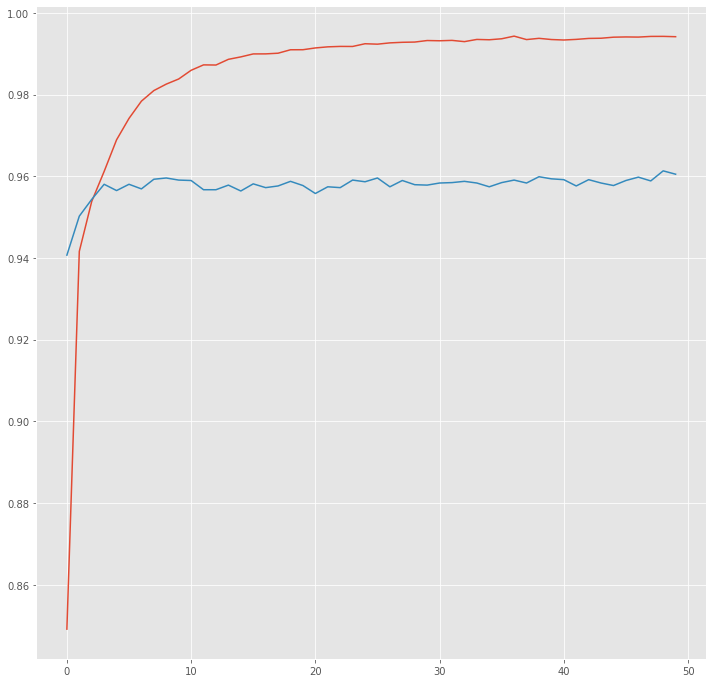

In [90]:
# Plot the acc and val_acc through the training process
hist = pd.DataFrame(history.history)
plt.style.use("ggplot")
plt.figure(figsize=(12,12))
plt.plot(hist["acc"])
plt.plot(hist["val_acc"])
plt.show()

In [91]:
# evaluate the model over the testing data
y_pred = model.predict([np.array(X_word_te).reshape(len(X_word_te), 18),
                        np.array(X_n3gram_word_te).reshape(len(X_n3gram_word_te), 18)])

In [92]:
# out the predicted value and actual values to lists
Token,yacttagall,ypredtagall,segall,predsegall,actstagMix,predstagMix,segsMix,segpredsMix,Segment= get_data(X_word_te,y_te,y_pred)

In [93]:
# Measure accuracy
print(accuracy_score(yacttagall,ypredtagall))
print(accuracy_score(actstagMix,predstagMix))

0.9352966777890613
0.4482758620689655


In [95]:
# Print the classification report for all test and mixed data tagging including the F-score
print(classification_report(yacttagall,ypredtagall,digits=4))
print(classification_report(actstagMix,predstagMix,digits=4))

                         precision    recall  f1-score   support

                  AMBIG     0.3750    0.2000    0.2609        15
                     AR     0.9660    0.9706    0.9683      4357
                  AR,EN     0.8095    0.7816    0.7953       174
               AR,EN,AR     0.2400    0.7500    0.3636         8
            AR,EN,AR,EN     0.0000    0.0000    0.0000         0
         AR,EN,NE.AR,AR     0.0000    0.0000    0.0000         0
               AR,NE.AR     0.0000    0.0000    0.0000         0
            AR,NE.AR,AR     0.0000    0.0000    0.0000         0
      AR,NE.AR,AR,NE.AR     0.0000    0.0000    0.0000         0
      AR,NE.AR,EN,NE.AR     0.0000    0.0000    0.0000         0
      AR,NE.AR,OTHER,EN     0.0000    0.0000    0.0000         0
               AR,OTHER     0.0000    0.0000    0.0000         0
            AR,OTHER,AR     0.0000    0.0000    0.0000         0
      AR,OTHER,AR,OTHER     0.0000    0.0000    0.0000         0
            AR,OTHER,EN 

In [96]:
# Print the classification report for all test and mixed data segmentation including the F-score
print(classification_report(segall,predsegall,digits=6))
print(classification_report(segsMix,segpredsMix,digits=6))

              precision    recall  f1-score   support

           1   1.000000  1.000000  1.000000       880
         1,1   0.000000  0.000000  0.000000         0
       1,1,1   0.000000  0.000000  0.000000         0
     1,1,1,1   0.000000  0.000000  0.000000         0
      1,1,10   0.000000  0.000000  0.000000         0
       1,1,2   0.000000  0.000000  0.000000         0
     1,1,2,1   0.000000  0.000000  0.000000         0
     1,1,2,2   0.000000  0.000000  0.000000         0
     1,1,2,3   0.000000  0.000000  0.000000         0
       1,1,3   0.333333  1.000000  0.500000         1
     1,1,3,2   0.000000  0.000000  0.000000         0
       1,1,4   0.000000  0.000000  0.000000         0
       1,1,6   0.000000  0.000000  0.000000         1
        1,11   1.000000  0.500000  0.666667         2
        1,15   0.000000  0.000000  0.000000         1
         1,2   0.333333  1.000000  0.500000         1
       1,2,1   0.000000  0.000000  0.000000         0
     1,2,1,1   0.000000  0.

In [97]:
print(get_Char_accuracy(yacttagall,segall,ypredtagall,predsegall))
print(get_Char_accuracy(actstagMix,segsMix,predstagMix,segpredsMix))

0.9416666666666667
0.7487227124941942


In [98]:
# Visualize Performance
print("{:15}||{:10}||{:10}||{:10}||{:10}||{:5}".format("Word", "True", "Pred","True Seg","Pred Seg","Segment"))
print(73 * "=")
for w, t, pred, trueSeg, predSeg, seg in zip(Token, yacttagall, ypredtagall, segall, predsegall, Segment):
    if w != 0:
        print("{:15}||{:10}||{:10}||{:10}||{:10}||{:5}".format(w, t, pred, trueSeg, predSeg, seg))

Word           ||True      ||Pred      ||True Seg  ||Pred Seg  ||Segment
أنا            ||AR        ||AR        ||3         ||3         ||أنا/AR
متفق           ||AR        ||AR        ||4         ||4         ||متفق/AR
معاك           ||AR        ||AR        ||4         ||4         ||معاك/AR
إن             ||AR        ||AR        ||2         ||2         ||إن/AR
الجو           ||AR        ||AR        ||4         ||4         ||الجو/AR
برد            ||AR        ||AR        ||3         ||3         ||برد/AR
لكن            ||AR        ||AR        ||3         ||3         ||لكن/AR
مش             ||AR        ||AR        ||2         ||2         ||مش/AR
معنى           ||AR        ||AR        ||4         ||4         ||معنى/AR
كده            ||AR        ||AR        ||3         ||3         ||كده/AR
انك            ||AR        ||AR        ||3         ||3         ||انك/AR
تبوظ           ||AR        ||AR        ||4         ||4         ||تبوظ/AR
اللاب          ||AR,EN     ||AR,EN     ||2,3       ||2,3    

copy           ||EN        ||EN        ||4         ||4         ||copy/EN
paste          ||EN        ||EN        ||5         ||5         ||paste/EN
we             ||EN        ||EN        ||2         ||2         ||we/EN
y7oto          ||AR        ||AR        ||5         ||5         ||y7oto/AR
cases          ||EN        ||EN        ||5         ||5         ||cases/EN
flterminal     ||AR,EN     ||AR,EN     ||2,8       ||2,8       ||fl/AR,terminal/EN
?              ||OTHER     ||OTHER     ||1         ||1         ||?/OTHER
hwa            ||AR        ||AR        ||3         ||3         ||hwa/AR
tabee3y        ||AR        ||AR        ||7         ||7         ||tabee3y/AR
eny            ||AR        ||AR        ||3         ||3         ||eny/AR
msh            ||AR        ||AR        ||3         ||3         ||msh/AR
fahma          ||AR        ||AR        ||5         ||5         ||fahma/AR
7aga           ||AR        ||AR        ||4         ||4         ||7aga/AR
kda            ||AR        ||AR        

zone           ||EN        ||EN        ||4         ||4         ||zone/EN
😂👏             ||OTHER     ||OTHER     ||2         ||2         ||😂👏/OTHER
احسن           ||AR        ||AR        ||4         ||4         ||احسن/AR
برده           ||AR        ||AR        ||4         ||4         ||برده/AR
msh            ||AR        ||AR        ||3         ||3         ||msh/AR
fahma          ||AR        ||AR        ||5         ||5         ||fahma/AR
di             ||AR        ||AR        ||2         ||2         ||di/AR
tho            ||AMBIG     ||EN        ||3         ||3         ||tho/EN
🤔              ||OTHER     ||OTHER     ||1         ||1         ||🤔/OTHER
heya           ||AR        ||AR        ||4         ||4         ||heya/AR
floffice       ||AR,EN     ||AR,EN     ||2,6       ||2,6       ||fl/AR,office/EN
el             ||AR        ||AR        ||2         ||2         ||el/AR
gowa           ||AR        ||AR        ||4         ||4         ||gowa/AR
eloffice       ||AR,EN     ||AR,EN     ||2,6   

elw2at         ||AR        ||AR        ||6         ||6         ||elw2at/AR
bygri          ||AR        ||NE.AR     ||5         ||5         ||bygri/NE.AR
bsor3a         ||AR        ||AR        ||6         ||6         ||bsor3a/AR
leh            ||AR        ||AR        ||3         ||3         ||leh/AR
😣🙁🙁🙁           ||OTHER     ||EN,AR     ||4         ||3,1       ||😣🙁🙁/EN,🙁/AR
حسنا           ||OTHER     ||AR        ||4         ||4         ||حسنا/AR
وللمرة         ||AR        ||AR        ||6         ||6         ||وللمرة/AR
الثانية        ||AR        ||AR        ||7         ||7         ||الثانية/AR
،              ||OTHER     ||OTHER     ||1         ||1         ||،/OTHER
إذا            ||AR        ||AR        ||3         ||3         ||إذا/AR
أردت           ||AR        ||AR        ||4         ||4         ||أردت/AR
ممارسة         ||AR        ||AR        ||6         ||6         ||ممارسة/AR
التمارين       ||AR        ||AR        ||8         ||8         ||التمارين/AR
هذا            ||AR        ||A

### Useing the model 

In [99]:

predicts(["ana","reh","ellab","now"],2)

['AR',
 'ana/AR',
 'NE.AR,AR',
 're/NE.AR,h/AR',
 'AR,EN',
 'el/AR,lab/EN',
 'EN',
 'now/EN']

In [49]:

predicts(["أنا","رايح","اللاب","ناو"],2)

['AR', 'أنا/AR', 'AR', 'رايح/AR', 'AR,EN', 'ال/AR,لاب/EN', 'AR', 'ناو/AR']

## The Model trained on char and 2gram char Features

In [50]:
# input and embedding for character
token_in = Input(shape=(18,))
emb_token = Embedding(input_dim=n_chars + 2, output_dim=20,
                     input_length=18, mask_zero=True)(token_in)

# input and embeddings for ngram
ngram_in = Input(shape=(18,))
emb_ngram = Embedding(input_dim=n_n2gram + 2, output_dim=20,
                           input_length=18, mask_zero=True)(ngram_in)

x = concatenate([emb_token, emb_ngram])
x = SpatialDropout1D(0.3)(x)

# main LSTM
main_lstm = Bidirectional(LSTM(units=50, return_sequences=True,
                               recurrent_dropout=0.6))(x)

out = TimeDistributed(Dense(n_tags + 2, activation="softmax"))(main_lstm)

model = Model([token_in,ngram_in], out)

In [51]:
# add the hyperparameters of the model
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["acc"])

In [52]:
model.summary()

Model: "model_4"
__________________________________________________________________________________________________
Layer (type)                    Output Shape         Param #     Connected to                     
input_5 (InputLayer)            (None, 18)           0                                            
__________________________________________________________________________________________________
input_6 (InputLayer)            (None, 18)           0                                            
__________________________________________________________________________________________________
embedding_5 (Embedding)         (None, 18, 20)       5100        input_5[0][0]                    
__________________________________________________________________________________________________
embedding_6 (Embedding)         (None, 18, 20)       43700       input_6[0][0]                    
____________________________________________________________________________________________

In [53]:
# Train the model
history = model.fit([np.array(X_word_tr).reshape(len(X_word_tr), 18),
                    np.array(X_n2gram_word_tr).reshape(len(X_n2gram_word_tr), 18)],
                    np.array(y_tr).reshape(len(y_tr), 18, 1),
                    batch_size=32, epochs=50, validation_split=0.1, verbose=1)

Train on 21085 samples, validate on 2343 samples
Epoch 1/50
21085/21085 [==============================] - 24s 1ms/step - loss: 0.1376 - acc: 0.8378 - val_loss: 0.0646 - val_acc: 0.9235
Epoch 2/50
21085/21085 [==============================] - 22s 1ms/step - loss: 0.0678 - acc: 0.9165 - val_loss: 0.0543 - val_acc: 0.9336
Epoch 3/50
21085/21085 [==============================] - 20s 943us/step - loss: 0.0590 - acc: 0.9247 - val_loss: 0.0494 - val_acc: 0.9373
Epoch 4/50
21085/21085 [==============================] - 20s 972us/step - loss: 0.0536 - acc: 0.9320 - val_loss: 0.0480 - val_acc: 0.9399
Epoch 5/50
21085/21085 [==============================] - 20s 961us/step - loss: 0.0495 - acc: 0.9364 - val_loss: 0.0447 - val_acc: 0.9450
Epoch 6/50
21085/21085 [==============================] - 20s 931us/step - loss: 0.0461 - acc: 0.9405 - val_loss: 0.0442 - val_acc: 0.9473
Epoch 7/50
21085/21085 [==============================] - 21s 982us/step - loss: 0.0430 - acc: 0.9437 - val_loss: 0.0438 

### Model Statics 

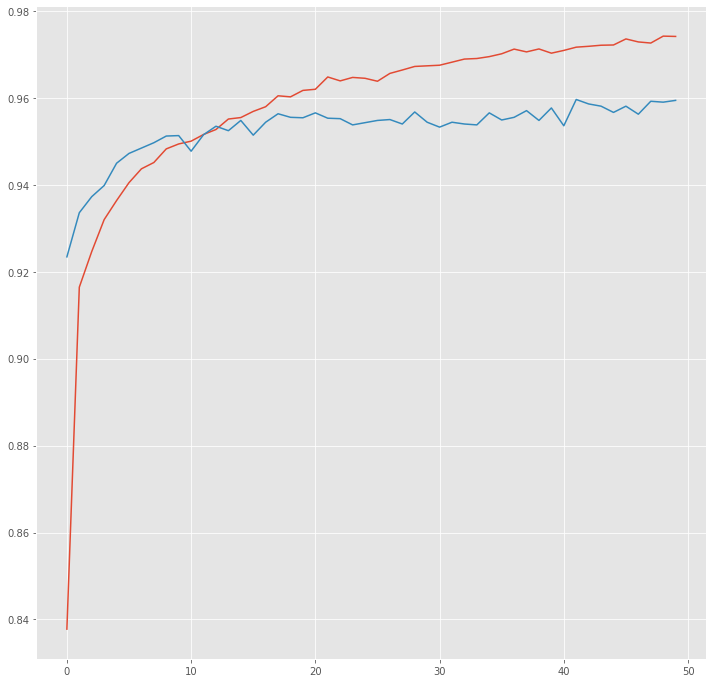

In [54]:
# Plot the acc and val_acc through the training process
hist = pd.DataFrame(history.history)
plt.style.use("ggplot")
plt.figure(figsize=(12,12))
plt.plot(hist["acc"])
plt.plot(hist["val_acc"])
plt.show()

In [55]:
# evaluate the model over the testing data
y_pred = model.predict([np.array(X_word_te).reshape(len(X_word_te), 18),
                        np.array(X_n2gram_word_te).reshape(len(X_n2gram_word_te), 18)])

In [56]:
# out the predicted value and actual values to lists
Token,yacttagall,ypredtagall,segall,predsegall,actstagMix,predstagMix,segsMix,segpredsMix,Segment= get_data(X_word_te,y_te,y_pred)

In [57]:
# Measure accuracy
print(accuracy_score(yacttagall,ypredtagall))
print(accuracy_score(actstagMix,predstagMix))

0.9278978674017119
0.42492917847025496


In [59]:
# Print the classification report for all test and mixed data tagging including the F-score
print(classification_report(yacttagall,ypredtagall,digits=4))
print(classification_report(actstagMix,predstagMix,digits=4))

                   precision    recall  f1-score   support

            AMBIG     0.5000    0.2000    0.2857        15
               AR     0.9603    0.9713    0.9658      4357
      AR,AMBIG,AR     0.0000    0.0000    0.0000         0
            AR,EN     0.8122    0.8448    0.8282       174
         AR,EN,AR     0.1429    0.3750    0.2069         8
      AR,EN,AR,EN     0.0000    0.0000    0.0000         0
   AR,EN,AR,EN,AR     0.0000    0.0000    0.0000         0
      AR,EN,NE.EN     0.0000    0.0000    0.0000         0
         AR,NE.AR     0.0000    0.0000    0.0000         0
      AR,NE.AR,AR     0.0000    0.0000    0.0000         0
AR,NE.AR,AR,NE.AR     0.0000    0.0000    0.0000         0
AR,NE.AR,EN,NE.AR     0.0000    0.0000    0.0000         0
         AR,NE.EN     0.0000    0.0000    0.0000         0
      AR,NE.EN,AR     0.0000    0.0000    0.0000         0
         AR,OTHER     0.0000    0.0000    0.0000         0
      AR,OTHER,EN     0.0000    0.0000    0.0000       

In [60]:
# Print the classification report for all test and mixed data segmentation including the F-score
print(classification_report(segall,predsegall,digits=6))
print(classification_report(segsMix,segpredsMix,digits=6))

              precision    recall  f1-score   support

           1   1.000000  1.000000  1.000000       880
         1,1   0.000000  0.000000  0.000000         0
       1,1,1   0.000000  0.000000  0.000000         0
     1,1,1,1   0.000000  0.000000  0.000000         0
     1,1,1,3   0.000000  0.000000  0.000000         0
     1,1,1,5   0.000000  0.000000  0.000000         0
     1,1,1,7   0.000000  0.000000  0.000000         0
       1,1,2   0.000000  0.000000  0.000000         0
     1,1,2,1   0.000000  0.000000  0.000000         0
   1,1,2,1,1   0.000000  0.000000  0.000000         0
     1,1,2,2   0.000000  0.000000  0.000000         0
       1,1,3   0.000000  0.000000  0.000000         1
     1,1,3,1   0.000000  0.000000  0.000000         0
       1,1,4   0.000000  0.000000  0.000000         0
     1,1,4,1   0.000000  0.000000  0.000000         0
       1,1,5   0.000000  0.000000  0.000000         0
       1,1,6   0.000000  0.000000  0.000000         1
       1,1,7   0.000000  0.

In [61]:
print(get_Char_accuracy(yacttagall,segall,ypredtagall,predsegall))
print(get_Char_accuracy(actstagMix,segsMix,predstagMix,segpredsMix))

0.9377285513361463
0.7464788732394366


In [62]:
# Visualize Performance
print("{:15}||{:10}||{:10}||{:10}||{:10}||{:5}".format("Word", "True", "Pred","True Seg","Pred Seg","Segment"))
print(73 * "=")
for w, t, pred, trueSeg, predSeg, seg in zip(Token, yacttagall, ypredtagall, segall, predsegall, Segment):
    if w != 0:
        print("{:15}||{:10}||{:10}||{:10}||{:10}||{:5}".format(w, t, pred, trueSeg, predSeg, seg))

Word           ||True      ||Pred      ||True Seg  ||Pred Seg  ||Segment
أنا            ||AR        ||AR        ||3         ||3         ||أنا/AR
متفق           ||AR        ||AR        ||4         ||4         ||متفق/AR
معاك           ||AR        ||AR        ||4         ||4         ||معاك/AR
إن             ||AR        ||AR        ||2         ||2         ||إن/AR
الجو           ||AR        ||AR        ||4         ||4         ||الجو/AR
برد            ||AR        ||EN,NE.EN  ||3         ||1,2       ||ب/EN,رد/NE.EN
لكن            ||AR        ||AR        ||3         ||3         ||لكن/AR
مش             ||AR        ||AR        ||2         ||2         ||مش/AR
معنى           ||AR        ||AR        ||4         ||4         ||معنى/AR
كده            ||AR        ||AR        ||3         ||3         ||كده/AR
انك            ||AR        ||AR        ||3         ||3         ||انك/AR
تبوظ           ||AR        ||AR        ||4         ||4         ||تبوظ/AR
اللاب          ||AR,EN     ||AR,EN     ||2,3       ||

ana            ||AR        ||AR        ||3         ||3         ||ana/AR
me7tag         ||AR        ||AR        ||6         ||6         ||me7tag/AR
header         ||EN        ||EN        ||6         ||6         ||header/EN
el             ||AR        ||AR        ||2         ||2         ||el/AR
raqam          ||AR        ||AR        ||5         ||5         ||raqam/AR
mesh           ||AR        ||AR        ||4         ||4         ||mesh/AR
hayenfa3       ||AR        ||AR        ||8         ||8         ||hayenfa3/AR
yet7at         ||AR        ||AR        ||6         ||6         ||yet7at/AR
f              ||AR        ||AR        ||1         ||1         ||f/AR 
one            ||EN        ||EN        ||3         ||3         ||one/EN
register       ||EN        ||EN        ||8         ||8         ||register/EN
aw             ||AR        ||AR        ||2         ||2         ||aw/AR
f              ||AR        ||AR        ||1         ||1         ||f/AR 
makan          ||AR        ||AR        ||5    

lazem          ||AR        ||AR        ||5         ||5         ||lazem/AR
abstract       ||EN        ||EN,AR,EN,AR,EN||8         ||1,2,1,2,2 ||a/EN,bs/AR,t/EN,ra/AR,ct/EN
w              ||AR        ||AR        ||1         ||1         ||w/AR 
heya           ||AR        ||AR        ||4         ||4         ||heya/AR
fe3lan         ||AR        ||AR        ||6         ||6         ||fe3lan/AR
abstract       ||EN        ||EN,AR,EN,AR,EN||8         ||1,2,1,2,2 ||a/EN,bs/AR,t/EN,ra/AR,ct/EN
3ashan         ||AR        ||AR        ||6         ||6         ||3ashan/AR
keda           ||AR        ||AR        ||4         ||4         ||keda/AR
malhash        ||AR        ||AR        ||7         ||7         ||malhash/AR
body           ||EN        ||AR        ||4         ||4         ||body/AR
shokran        ||AR        ||AR        ||7         ||7         ||shokran/AR
😂🙌🏽            ||OTHER     ||OTHER     ||3         ||3         ||😂🙌🏽/OTHER
نفس            ||AR        ||AR        ||3         ||3         ||

بنسبة          ||AR        ||AR        ||5         ||5         ||بنسبة/AR
كبيرة          ||AR        ||AR        ||5         ||5         ||كبيرة/AR
جدا            ||AR        ||AR        ||3         ||3         ||جدا/AR
جدا            ||AR        ||AR        ||3         ||3         ||جدا/AR
و              ||AR        ||AR        ||1         ||1         ||و/AR 
دا             ||AR        ||AR        ||2         ||2         ||دا/AR
شيء            ||AR        ||AR        ||3         ||3         ||شيء/AR
نادر           ||AR        ||AR        ||4         ||4         ||نادر/AR
الحدوث         ||AR        ||AR        ||6         ||6         ||الحدوث/AR
لان            ||AR        ||AR        ||3         ||3         ||لان/AR
استخدامي       ||AR        ||AR        ||8         ||8         ||استخدامي/AR
الدائم         ||AR        ||AR        ||6         ||6         ||الدائم/AR
ل              ||AR        ||AR        ||1         ||1         ||ل/AR 
اللاب          ||AR,EN     ||AR,EN     ||2,3       

المصاب         ||AR        ||AR        ||6         ||6         ||المصاب/AR
بالتوحد        ||AR        ||AR        ||7         ||7         ||بالتوحد/AR
،              ||OTHER     ||OTHER     ||1         ||1         ||،/OTHER
الناس          ||AR        ||AR        ||5         ||5         ||الناس/AR
دي             ||AR        ||AR        ||2         ||2         ||دي/AR
مثيرة          ||AR        ||AR        ||5         ||5         ||مثيرة/AR
للضجة          ||AR        ||AR        ||5         ||5         ||للضجة/AR
،              ||OTHER     ||OTHER     ||1         ||1         ||،/OTHER
بيزعجوا        ||AR        ||AR        ||7         ||7         ||بيزعجوا/AR
الناس          ||AR        ||AR        ||5         ||5         ||الناس/AR
،              ||OTHER     ||OTHER     ||1         ||1         ||،/OTHER
بيدخلوا        ||AR        ||AR        ||7         ||7         ||بيدخلوا/AR
في             ||AR        ||AR        ||2         ||2         ||في/AR
نقاشات         ||AR        ||AR        |

### Useing the model

In [63]:

predicts(["ana","reh","ellab","now"],1)

['AR', 'ana/AR', 'AR', 'reh/AR', 'AR,EN', 'el/AR,lab/EN', 'EN', 'now/EN']

In [64]:

predicts(["أنا","رايح","اللاب","ناو"],1)

['AR', 'أنا/AR', 'AR', 'رايح/AR', 'AR,EN', 'ال/AR,لاب/EN', 'AR', 'ناو/AR']

## The Model trained on char , 2gram char and 3gram char Features

In [65]:
# input and embedding for character
token_in = Input(shape=(18,))
emb_token = Embedding(input_dim=n_chars + 2, output_dim=20,
                     input_length=18, mask_zero=True)(token_in)

# input and embeddings for 2 gram
n2gram_in = Input(shape=(18,))
emb_n2gram = Embedding(input_dim=n_n2gram + 2, output_dim=20,
                           input_length=18, mask_zero=True)(n2gram_in)

# input and embeddings for 3 gram
n3gram_in = Input(shape=(18,))
emb_n3gram = Embedding(input_dim=n_n3gram + 2, output_dim=20,
                           input_length=18, mask_zero=True)(n3gram_in)

x = concatenate([emb_token, emb_n2gram, emb_n3gram])
x = SpatialDropout1D(0.3)(x)

# main LSTM
main_lstm = Bidirectional(LSTM(units=50, return_sequences=True,
                               recurrent_dropout=0.6))(x)

out = TimeDistributed(Dense(n_tags + 2, activation="softmax"))(main_lstm)

model3 = Model([token_in, n2gram_in, n3gram_in], out)

In [66]:
# add the hyperparameters of the model
model3.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["acc"])

In [67]:
model3.summary()

Model: "model_5"
__________________________________________________________________________________________________
Layer (type)                    Output Shape         Param #     Connected to                     
input_7 (InputLayer)            (None, 18)           0                                            
__________________________________________________________________________________________________
input_8 (InputLayer)            (None, 18)           0                                            
__________________________________________________________________________________________________
input_9 (InputLayer)            (None, 18)           0                                            
__________________________________________________________________________________________________
embedding_7 (Embedding)         (None, 18, 20)       5100        input_7[0][0]                    
____________________________________________________________________________________________

In [68]:
# Train the model
history3 = model3.fit([np.array(X_word_tr).reshape(len(X_word_tr), 18),
                    np.array(X_n2gram_word_tr).reshape(len(X_n2gram_word_tr), 18),
                    np.array(X_n3gram_word_tr).reshape(len(X_n3gram_word_tr), 18)],
                    np.array(y_tr).reshape(len(y_tr), 18, 1),
                    batch_size=32, epochs=50, validation_split=0.1, verbose=1)

Train on 21085 samples, validate on 2343 samples
Epoch 1/50
21085/21085 [==============================] - 26s 1ms/step - loss: 0.1222 - acc: 0.8605 - val_loss: 0.0500 - val_acc: 0.9450
Epoch 2/50
21085/21085 [==============================] - 24s 1ms/step - loss: 0.0475 - acc: 0.9438 - val_loss: 0.0423 - val_acc: 0.9544
Epoch 3/50
21085/21085 [==============================] - 25s 1ms/step - loss: 0.0348 - acc: 0.9559 - val_loss: 0.0400 - val_acc: 0.9578
Epoch 4/50
21085/21085 [==============================] - 23s 1ms/step - loss: 0.0273 - acc: 0.9651 - val_loss: 0.0395 - val_acc: 0.9589
Epoch 5/50
21085/21085 [==============================] - 23s 1ms/step - loss: 0.0217 - acc: 0.9719 - val_loss: 0.0411 - val_acc: 0.9640
Epoch 6/50
21085/21085 [==============================] - 23s 1ms/step - loss: 0.0182 - acc: 0.9763 - val_loss: 0.0401 - val_acc: 0.9606
Epoch 7/50
21085/21085 [==============================] - 23s 1ms/step - loss: 0.0152 - acc: 0.9789 - val_loss: 0.0410 - val_acc:

### Model Statics 

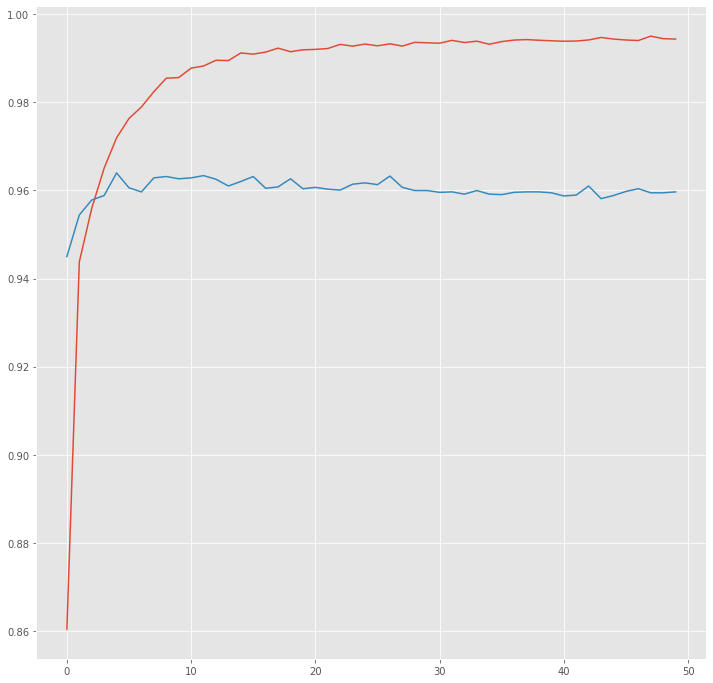

In [70]:
# Plot the acc and val_acc through the training process
hist3 = pd.DataFrame(history3.history)
plt.style.use("ggplot")
plt.figure(figsize=(12,12))
plt.plot(hist3["acc"])
plt.plot(hist3["val_acc"])
plt.show()

In [71]:
# evaluate the model over the testing data
y_pred3 = model3.predict([np.array(X_word_te).reshape(len(X_word_te), 18),
                        np.array(X_n2gram_word_te).reshape(len(X_n2gram_word_te), 18),
                        np.array(X_n3gram_word_te).reshape(len(X_n3gram_word_te), 18)])

In [72]:
# out the predicted value and actual values to lists
Token,yacttagall,ypredtagall,segall,predsegall,actstagMix,predstagMix,segsMix,segpredsMix,Segment= get_data(X_word_te,y_te,y_pred3)

In [73]:
# Measure accuracy
print(accuracy_score(yacttagall,ypredtagall))
print(accuracy_score(actstagMix,predstagMix))

0.936167126069926
0.4819672131147541


In [75]:
# Print the classification report for all test and mixed data tagging including the F-score
print(classification_report(yacttagall,ypredtagall,digits=4))
print(classification_report(actstagMix,predstagMix,digits=4))

                         precision    recall  f1-score   support

                  AMBIG     0.4286    0.2000    0.2727        15
            AMBIG,NE.AR     0.0000    0.0000    0.0000         0
                     AR     0.9658    0.9715    0.9686      4357
               AR,AMBIG     0.0000    0.0000    0.0000         0
                  AR,EN     0.8571    0.7931    0.8239       174
               AR,EN,AR     0.2500    0.8750    0.3889         8
            AR,EN,AR,EN     0.0000    0.0000    0.0000         0
         AR,EN,AR,EN,AR     0.0000    0.0000    0.0000         0
            AR,EN,OTHER     0.0000    0.0000    0.0000         0
               AR,NE.AR     0.0000    0.0000    0.0000         0
            AR,NE.AR,AR     0.0000    0.0000    0.0000         0
      AR,NE.AR,EN,NE.AR     0.0000    0.0000    0.0000         0
               AR,NE.EN     0.0000    0.0000    0.0000         0
            AR,NE.EN,EN     0.0000    0.0000    0.0000         0
               AR,OTHER 

In [76]:
# Print the classification report for all test and mixed data segmentation including the F-score
print(classification_report(segall,predsegall,digits=6))
print(classification_report(segsMix,segpredsMix,digits=6))

              precision    recall  f1-score   support

           1   1.000000  1.000000  1.000000       880
       1,1,1   0.000000  0.000000  0.000000         0
     1,1,1,1   0.000000  0.000000  0.000000         0
     1,1,1,3   0.000000  0.000000  0.000000         0
       1,1,2   0.000000  0.000000  0.000000         0
     1,1,2,2   0.000000  0.000000  0.000000         0
       1,1,3   0.142857  1.000000  0.250000         1
     1,1,3,1   0.000000  0.000000  0.000000         0
       1,1,4   0.000000  0.000000  0.000000         0
     1,1,4,1   0.000000  0.000000  0.000000         0
       1,1,6   0.500000  1.000000  0.666667         1
        1,11   1.000000  0.500000  0.666667         2
        1,15   0.000000  0.000000  0.000000         1
         1,2   0.142857  1.000000  0.250000         1
       1,2,1   0.000000  0.000000  0.000000         0
     1,2,1,1   0.000000  0.000000  0.000000         0
   1,2,1,1,1   0.000000  0.000000  0.000000         0
       1,2,5   0.000000  0.

In [77]:
print(get_Char_accuracy(yacttagall,segall,ypredtagall,predsegall))
print(get_Char_accuracy(actstagMix,segsMix,predstagMix,segpredsMix))

0.9422292545710267
0.7801621363853124


In [78]:
# Visualize Performance
print("{:15}||{:10}||{:10}||{:10}||{:10}||{:5}".format("Word", "True", "Pred","True Seg","Pred Seg","Segment"))
print(73 * "=")
for w, t, pred, trueSeg, predSeg, seg in zip(Token, yacttagall, ypredtagall, segall, predsegall, Segment):
    if w != 0:
        print("{:15}||{:10}||{:10}||{:10}||{:10}||{:5}".format(w, t, pred, trueSeg, predSeg, seg))

Word           ||True      ||Pred      ||True Seg  ||Pred Seg  ||Segment
أنا            ||AR        ||AR        ||3         ||3         ||أنا/AR
متفق           ||AR        ||AR        ||4         ||4         ||متفق/AR
معاك           ||AR        ||AR        ||4         ||4         ||معاك/AR
إن             ||AR        ||AR        ||2         ||2         ||إن/AR
الجو           ||AR        ||AR        ||4         ||4         ||الجو/AR
برد            ||AR        ||AR        ||3         ||3         ||برد/AR
لكن            ||AR        ||AR        ||3         ||3         ||لكن/AR
مش             ||AR        ||AR        ||2         ||2         ||مش/AR
معنى           ||AR        ||AR        ||4         ||4         ||معنى/AR
كده            ||AR        ||AR        ||3         ||3         ||كده/AR
انك            ||AR        ||AR        ||3         ||3         ||انك/AR
تبوظ           ||AR        ||AR        ||4         ||4         ||تبوظ/AR
اللاب          ||AR,EN     ||AR,EN     ||2,3       ||2,3    

elly           ||AR        ||AR        ||4         ||4         ||elly/AR
ta7taha        ||AR        ||AR        ||7         ||7         ||ta7taha/AR
3alatool       ||AR        ||AR        ||8         ||8         ||3alatool/AR
)              ||OTHER     ||OTHER     ||1         ||1         ||)/OTHER
😂😂😂😂👌🏻👌🏻       ||OTHER     ||OTHER     ||8         ||8         ||😂😂😂😂👌🏻👌🏻/OTHER
eh             ||AR        ||AR        ||2         ||2         ||eh/AR
el             ||AR        ||AR        ||2         ||2         ||el/AR
pas            ||EN        ||EN        ||3         ||3         ||pas/EN
eli            ||AR        ||AR        ||3         ||3         ||eli/AR
da5la          ||AR        ||AR        ||5         ||5         ||da5la/AR
fquiz          ||AR,EN     ||EN        ||1,4       ||5         ||fquiz/EN
elmedia        ||AR,EN     ||AR,EN     ||2,5       ||2,5       ||el/AR,media/EN
?              ||OTHER     ||OTHER     ||1         ||1         ||?/OTHER
hwa            ||AR        ||AR   

على            ||AR        ||AR        ||3         ||3         ||على/AR
للناس          ||AR        ||AR        ||5         ||5         ||للناس/AR
الخريجة        ||AR        ||AR        ||7         ||7         ||الخريجة/AR
من             ||AR        ||AR        ||2         ||2         ||من/AR
كليات          ||AR        ||AR        ||5         ||5         ||كليات/AR
الكومبيوتر     ||AR        ||AR        ||10        ||10        ||الكومبيوتر/AR
عموما          ||AR        ||AR        ||5         ||5         ||عموما/AR
بشكل           ||AR        ||AR        ||4         ||4         ||بشكل/AR
أقوى           ||AR        ||AR        ||4         ||4         ||أقوى/AR
.              ||OTHER     ||OTHER     ||1         ||1         ||./OTHER
m2olna         ||AR        ||AR        ||6         ||6         ||m2olna/AR
akhlas         ||AR        ||AR        ||6         ||6         ||akhlas/AR
elgam3a        ||AR        ||AR        ||7         ||7         ||elgam3a/AR
w              ||AR        ||AR    

0              ||OTHER     ||OTHER     ||1         ||1         ||0/OTHER
zyada          ||AR        ||AR        ||5         ||5         ||zyada/AR
3al            ||AR        ||AR        ||3         ||3         ||3al/AR
output         ||EN        ||EN        ||6         ||6         ||output/EN
?              ||OTHER     ||OTHER     ||1         ||1         ||?/OTHER
lel            ||AR        ||AR        ||3         ||3         ||lel/AR
asaf           ||AR        ||AR        ||4         ||4         ||asaf/AR
mesh           ||AR        ||AR        ||4         ||4         ||mesh/AR
la2i           ||AR        ||AR        ||4         ||4         ||la2i/AR
7aga           ||AR        ||AR        ||4         ||4         ||7aga/AR
3al            ||AR        ||AR        ||3         ||3         ||3al/AR
youtube        ||NE.EN     ||NE.EN     ||7         ||7         ||youtube/NE.EN
5ales          ||AR        ||AR        ||5         ||5         ||5ales/AR
ela            ||AR        ||AR        ||3  

### Useing the model 

In [79]:

predicts(["ana","reh","ellab","now"],3)

['AR', 'ana/AR', 'NE.AR', 'reh/NE.AR', 'AR,EN', 'el/AR,lab/EN', 'EN', 'now/EN']

In [80]:

predicts(["أنا","رايح","اللاب","ناو"],3)

['AR', 'أنا/AR', 'AR', 'رايح/AR', 'AR,EN', 'ال/AR,لاب/EN', 'AR', 'ناو/AR']